In [3]:
!python3 -m pip install pandas numpy scikit-learn matplotlib yellowbrick joblib

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 10.8 MB 47 kB/s eta 0:00:011
     |████████████████████████████████| 5.3 MB 176 kB/s eta 0:00:01
     |████████████████████████████████| 11.1 MB 853 kB/s eta 0:00:01
     |████████████████████████████████| 7.8 MB 1.7 MB/s eta 0:00:01
     |████████████████████████████████| 282 kB 814 kB/s eta 0:00:01
     |████████████████████████████████| 309 kB 875 kB/s eta 0:00:01
     |████████████████████████████████| 348 kB 702 kB/s eta 0:00:01    |█▉                              | 20 kB 523 kB/s eta 0:00:01
     |████████████████████████████████| 506 kB 431 kB/s eta 0:00:01
     |████████████████████████████████| 30.3 MB 72 kB/s eta 0:00:011    |██████████▏                     | 9.6 MB 101 kB/s eta 0:03:26     |██████████████▎                 | 13.5 MB 445 kB/s eta 0:00:38     |████████████████                | 15.1 MB 196 kB/s eta 0:01:18
     |████████████████████████████████| 

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from yellowbrick.classifier import ConfusionMatrix, ClassificationReport

print("-> Nạp thư viện thành công!")

Matplotlib is building the font cache; this may take a moment.


-> Nạp thư viện thành công!


In [5]:
train_df = pd.read_csv('data/train.csv')
val_df   = pd.read_csv('data/val.csv')
test_df  = pd.read_csv('data/test.csv')

for d in [train_df, val_df, test_df]:
    d.columns = d.columns.str.lower().str.strip()

print(f"Tập Train: {train_df.shape[0]} dòng")
print(f"Tập Val:   {val_df.shape[0]} dòng")
print(f"Tập Test:  {test_df.shape[0]} dòng")

Tập Train: 8393 dòng
Tập Val:   1799 dòng
Tập Test:  1799 dòng


In [6]:
X_train = train_df.drop('left', axis=1)
y_train = train_df['left']

X_val = val_df.drop('left', axis=1)
y_val = val_df['left']

X_test = test_df.drop('left', axis=1)
y_test = test_df['left']

cat_cols = ['salary', 'departments']
encoders = {}

for col in cat_cols:
    le = LabelEncoder()
    X_train[col] = le.fit_transform(X_train[col])
    X_val[col]   = le.transform(X_val[col])
    X_test[col]  = le.transform(X_test[col])
    encoders[col] = le

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)

print("-> Tiền xử lý hoàn tất chuẩn quy trình chống Data Leakage!")

-> Tiền xử lý hoàn tất chuẩn quy trình chống Data Leakage!


 ĐANG CHẠY MÔ HÌNH: Gradient Boosting Classifier


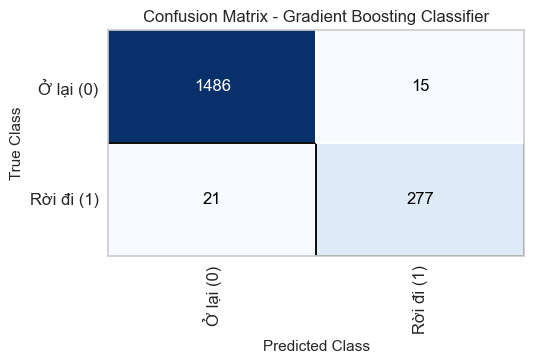

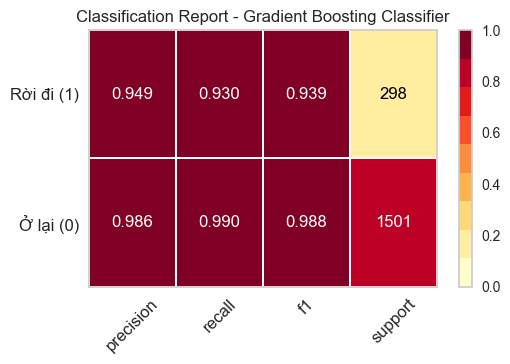



 ĐANG CHẠY MÔ HÌNH: K Neighbors Classifier (KNN)


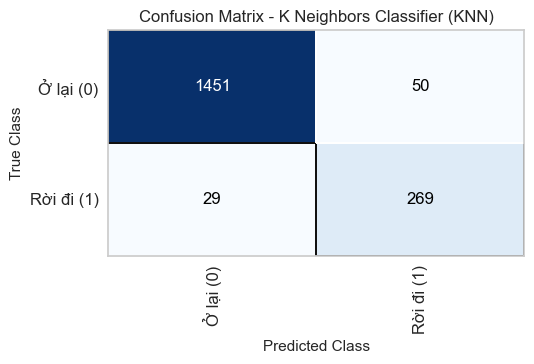

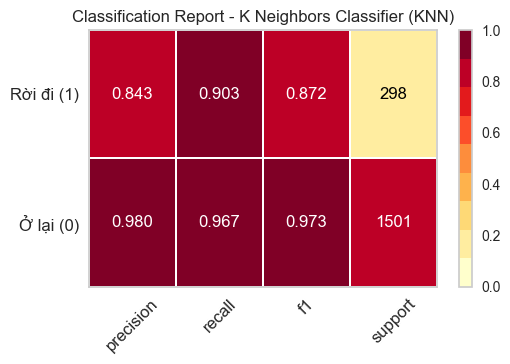



 ĐANG CHẠY MÔ HÌNH: Random Forest Classifier


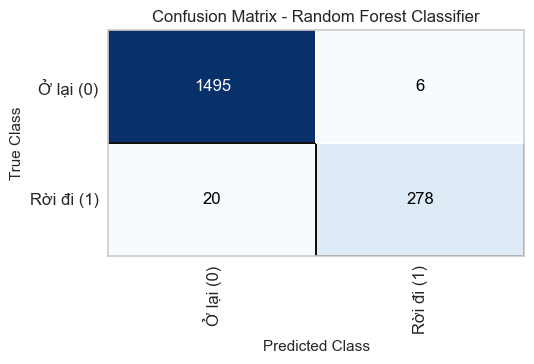

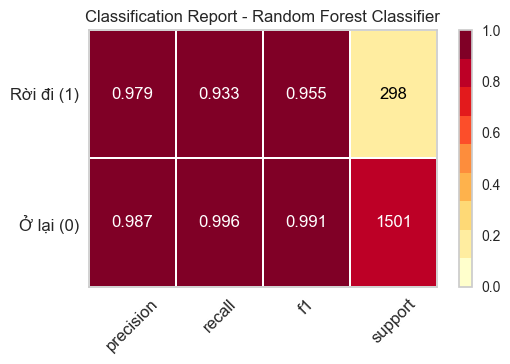



 BẢNG TỔNG HỢP HIỆU NĂNG MÔ HÌNH (TRÊN TẬP TEST)
                       Model  Accuracy  Precision   Recall  F1-Score
Gradient Boosting Classifier  0.979989   0.948630 0.929530  0.938983
K Neighbors Classifier (KNN)  0.956087   0.843260 0.902685  0.871961
    Random Forest Classifier  0.985548   0.978873 0.932886  0.955326


In [7]:
models = {
    "Gradient Boosting Classifier": GradientBoostingClassifier(random_state=42),
    "K Neighbors Classifier (KNN)": KNeighborsClassifier(),
    "Random Forest Classifier": RandomForestClassifier(random_state=42)
}

comparison_results = []

for name, model in models.items():
    print("=" * 60)
    print(f" ĐANG CHẠY MÔ HÌNH: {name}")
    print("=" * 60)
    
    # Huấn luyện trên tập Train
    model.fit(X_train_scaled, y_train)
    
    # Dự đoán trên tập Test
    y_pred = model.predict(X_test_scaled)
    
    comparison_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred)
    })
    
    # Confusion Matrix
    plt.figure(figsize=(5.5, 3.8))
    cm = ConfusionMatrix(model, classes=['Ở lại (0)', 'Rời đi (1)'], cmap='Blues', title=f'Confusion Matrix - {name}')
    cm.score(X_test_scaled, y_test)
    cm.show()
    
    # Classification Report
    plt.figure(figsize=(5.5, 3.8))
    cr = ClassificationReport(model, classes=['Ở lại (0)', 'Rời đi (1)'], support=True, title=f'Classification Report - {name}')
    cr.score(X_test_scaled, y_test)
    cr.show()
    print("\n")

# Bảng so sánh tổng kết
df_comp = pd.DataFrame(comparison_results)
print("=" * 60)
print(" BẢNG TỔNG HỢP HIỆU NĂNG MÔ HÌNH (TRÊN TẬP TEST)")
print("=" * 60)
print(df_comp.to_string(index=False))